In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Загружаем датасет
df = pd.read_csv('../data/Amazon Sale Report.csv', low_memory=False)


In [5]:
print(f"Размер таблицы (строки, столбцы): {df.shape}\n")

print("Типы столбцов:")
print(df.dtypes)
print("-" * 50)

print("\nКоличество пропусков по столбцам:")
print(df.isna().sum())

Размер таблицы (строки, столбцы): (128975, 24)

Типы столбцов:
index                   int64
Order ID                  str
Date                      str
Status                    str
Fulfilment                str
Sales Channel             str
ship-service-level        str
Style                     str
SKU                       str
Category                  str
Size                      str
ASIN                      str
Courier Status            str
Qty                     int64
currency                  str
Amount                float64
ship-city                 str
ship-state                str
ship-postal-code      float64
ship-country              str
promotion-ids             str
B2B                      bool
fulfilled-by              str
Unnamed: 22            object
dtype: object
--------------------------------------------------

Количество пропусков по столбцам:
index                     0
Order ID                  0
Date                      0
Status                    0
Fulfi

In [6]:
# Описание числовых столбцов (количество, среднее, квантили)
df.describe()

,index,Qty,Amount,ship-postal-code
count,128975.000000,128975.000000,121180.000000,128942.000000
mean,64487.000000,0.904431,648.561465,463966.236509
std,37232.019822,0.313354,281.211687,191476.764941
min,0.000000,0.000000,0.000000,110001.000000
25%,32243.500000,1.000000,449.000000,382421.000000
50%,64487.000000,1.000000,605.000000,500033.000000
75%,96730.500000,1.000000,788.000000,600024.000000
max,128974.000000,15.000000,5584.000000,989898.000000


/tmp/ipykernel_26691/3537050643.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Status', ax=axes[1], order=df['Status'].value_counts().iloc[:5].index, palette='Set2')


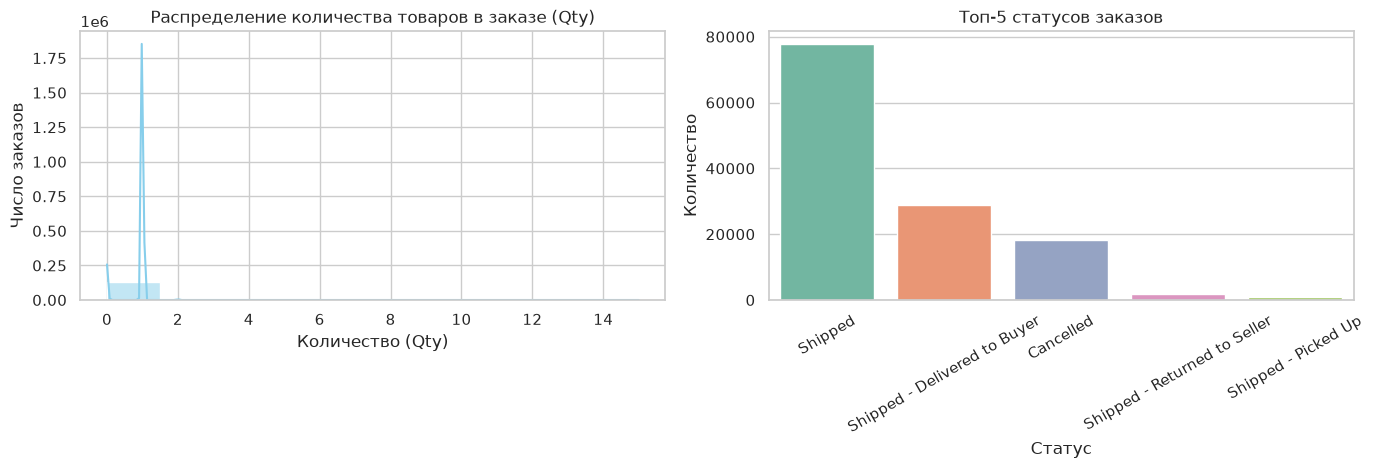

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Распределение числового признака (Qty — количество товара)
sns.histplot(df['Qty'].dropna(), bins=10, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Распределение количества товаров в заказе (Qty)')
axes[0].set_xlabel('Количество (Qty)')
axes[0].set_ylabel('Число заказов')

# 2. Соотношение категорий (Топ-5 статусов заказа)
sns.countplot(data=df, x='Status', ax=axes[1], order=df['Status'].value_counts().iloc[:5].index, palette='Set2')
axes[1].set_title('Топ-5 статусов заказов')
axes[1].set_xlabel('Статус')
axes[1].set_ylabel('Количество')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### Содержательные наблюдения по данным:

1. **Концентрация объемов заказов:** Подавляющее большинство клиентов покупает единовременно 1 штуку товара (Qty = 1), оптовые покупки из нескольких штук встречаются крайне редко.
2. **Состояние заказов:** Доминирующим статусом является "Shipped" (отправлено), что указывает на высокий процент успешно выполненных транзакций в выгрузке.
3. **Характер пропусков:** Пропуски не распределены случайно: основные финансовые и товарные параметры заполнены полностью, а пропуски сосредоточены во вспомогательных логистических полях (курьерские службы и данные доставки).